# 05. Weather Exploratory Data Analysis

## Objective

This notebook presents an exploratory analysis of the validated hourly weather observations for Delhi covering September 2024 to February 2025. It documents the distributions, temporal variation, associations, weather conditions, and extreme observations in the data before it is used as an input to later Delhi Metro ridership forecasting work.

The notebook is deliberately restricted to weather EDA: it does not construct features, merge weather with metro ridership, or fit forecasting or statistical models.

## 1. Import Libraries

Only libraries required for data handling and visualisation are imported. Display and plotting defaults are set once to promote consistent, publication-quality output throughout the notebook.

In [41]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({
    'figure.figsize': (11, 6),
    'figure.dpi': 110,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'axes.titlesize': 13
})

print('Libraries imported successfully.')

Libraries imported successfully.


## 2. Load Dataset

The analysis uses the cleaned hourly weather dataset exported by the Weather Data Integration notebook. The path is constructed relative to the project root so that the notebook remains reproducible when run from either the project directory or the `Notebooks` directory.

In [42]:
project_root = Path.cwd().resolve()
if project_root.name == 'Notebooks':
    project_root = project_root.parent

weather_path = project_root / 'DataProcessed' / 'weather_hourly_cleaned.csv'
weather = pd.read_csv(weather_path, parse_dates=['time'])

print(f'Dataset loaded from: {weather_path}')
print(f'Dataset shape: {weather.shape}')

Dataset loaded from: /Users/shivaya/Desktop/Research/DelhiMetroResearch/DataProcessed/weather_hourly_cleaned.csv
Dataset shape: (4344, 11)


## 3. Dataset Overview

This section establishes the analytical scope of the dataset by documenting its size, temporal coverage, variables, data types, and descriptive statistics. These checks provide a transparent baseline for the subsequent visual analysis.

In [43]:
print(f'Number of observations: {len(weather):,}')
print(f'Number of variables: {weather.shape[1]}')
print(f'Date range: {weather["time"].min():%d %B %Y %H:%M} to {weather["time"].max():%d %B %Y %H:%M}')
print('\nVariables:')
for column in weather.columns:
    print(f'  - {column}')

Number of observations: 4,344
Number of variables: 11
Date range: 01 September 2024 00:00 to 28 February 2025 23:00

Variables:
  - time
  - temperature_2m_c
  - relative_humidity_2m_pct
  - apparent_temperature_c
  - precipitation_mm
  - rain_mm
  - weather_code_wmo
  - surface_pressure_hpa
  - cloud_cover_pct
  - visibility_m
  - wind_speed_10m_kmh


In [44]:
data_types = weather.dtypes.rename('data_type').to_frame()
display(data_types)
print(f'Observation: the timestamp is stored as datetime and {weather.shape[1] - 1} weather measurements are numeric.')

,data_type
time,datetime64[us]
temperature_2m_c,float64
relative_humidity_2m_pct,int64
apparent_temperature_c,float64
precipitation_mm,float64
rain_mm,float64
weather_code_wmo,int64
surface_pressure_hpa,float64
cloud_cover_pct,int64
visibility_m,float64


Observation: the timestamp is stored as datetime and 10 weather measurements are numeric.


In [45]:
display(weather.describe().T)
print(
    f'Observation: temperature ranges from {weather["temperature_2m_c"].min():.1f}°C to '
    f'{weather["temperature_2m_c"].max():.1f}°C across the study period; '
    f'total precipitation is {weather["precipitation_mm"].sum():.1f} mm.'
)

,count,mean,min,25%,50%,75%,max,std
time,4344,2024-11-30 11:30:00,2024-09-01 00:00:00,2024-10-16 05:45:00,2024-11-30 11:30:00,2025-01-14 17:15:00,2025-02-28 23:00:00,NaN
temperature_2m_c,4344.00,20.87,6.60,15.30,21.10,26.00,35.20,6.71
relative_humidity_2m_pct,4344.00,68.20,19.00,53.75,71.00,85.00,100.00,19.92
apparent_temperature_c,4344.00,21.68,4.80,14.70,21.10,29.20,40.90,8.49
precipitation_mm,4344.00,0.10,0.00,0.00,0.00,0.00,13.20,0.71
rain_mm,4344.00,0.10,0.00,0.00,0.00,0.00,13.20,0.71
weather_code_wmo,4344.00,4.19,0.00,0.00,0.00,1.00,65.00,13.77
surface_pressure_hpa,4344.00,987.94,973.70,985.50,988.90,991.20,998.20,4.69
cloud_cover_pct,4344.00,21.38,0.00,0.00,0.00,25.00,100.00,36.49
visibility_m,4344.00,23436.97,300.00,24140.00,24140.00,24140.00,24140.00,2937.96


Observation: temperature ranges from 6.6°C to 35.2°C across the study period; total precipitation is 413.8 mm.


## 4. Univariate Analysis

The following subsections examine each weather variable independently. For continuous measures, descriptive statistics, a histogram, and a boxplot reveal central tendency, spread, skewness, and possible extreme values. Weather code is categorical and is therefore analysed through its frequency distribution in Section 7.

In [46]:
def describe_and_plot_continuous(data, column, label, unit, bins=30):
    """Display descriptive statistics and distribution plots for one continuous weather variable."""
    series = data[column].dropna()
    display(series.describe().to_frame(name=label))

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [2.2, 1]})
    sns.histplot(series, bins=bins, kde=True, color='#2878B5', ax=axes[0])
    axes[0].set(title=f'Distribution of {label}', xlabel=f'{label} ({unit})', ylabel='Frequency')

    sns.boxplot(x=series, color='#72B7B2', ax=axes[1])
    axes[1].set(title=f'Boxplot of {label}', xlabel=f'{label} ({unit})')
    plt.tight_layout()
    plt.show()

    print(
        f'Observation: mean = {series.mean():.2f} {unit}, median = {series.median():.2f} {unit}, '
        f'minimum = {series.min():.2f} {unit}, and maximum = {series.max():.2f} {unit}.'
    )

### 4.1 Temperature

Air temperature at 2 metres is the principal ambient-temperature measure. Its distribution indicates the range of thermal conditions experienced during the study period.

,Temperature at 2 m
count,4344.00
mean,20.87
std,6.71
min,6.60
25%,15.30
50%,21.10
75%,26.00
max,35.20


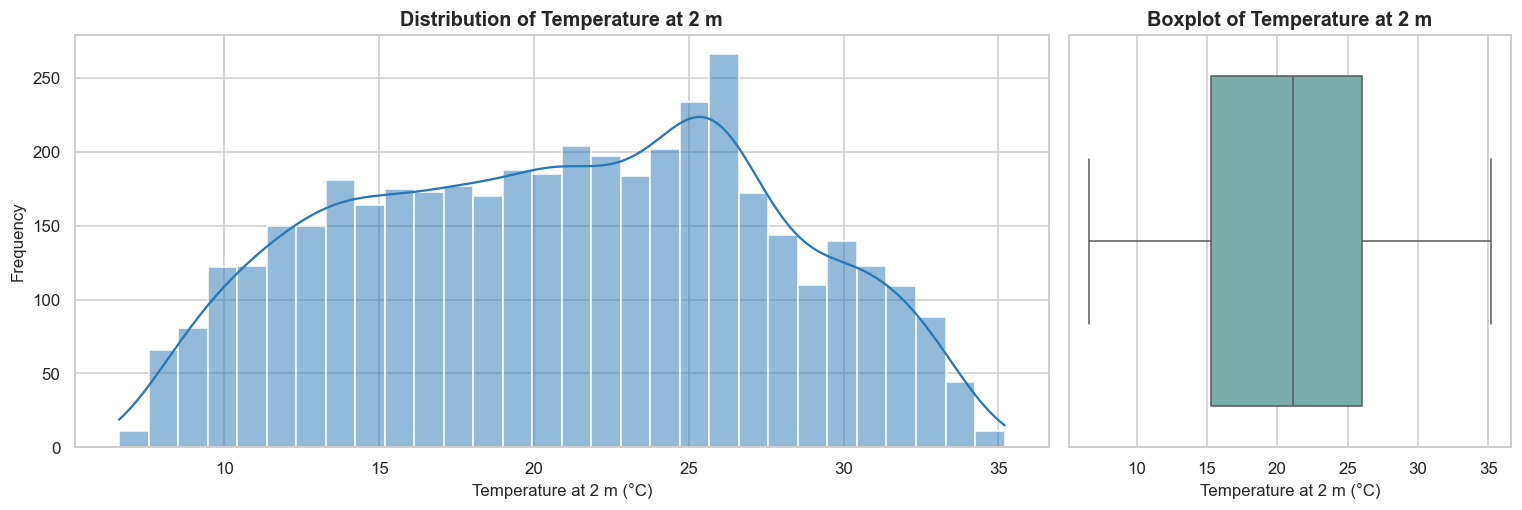

Observation: mean = 20.87 °C, median = 21.10 °C, minimum = 6.60 °C, and maximum = 35.20 °C.


In [47]:
describe_and_plot_continuous(weather, 'temperature_2m_c', 'Temperature at 2 m', '°C')

### 4.2 Apparent Temperature

Apparent temperature represents perceived outdoor temperature and incorporates the effect of atmospheric conditions beyond measured air temperature.

,Apparent Temperature
count,4344.00
mean,21.68
std,8.49
min,4.80
25%,14.70
50%,21.10
75%,29.20
max,40.90


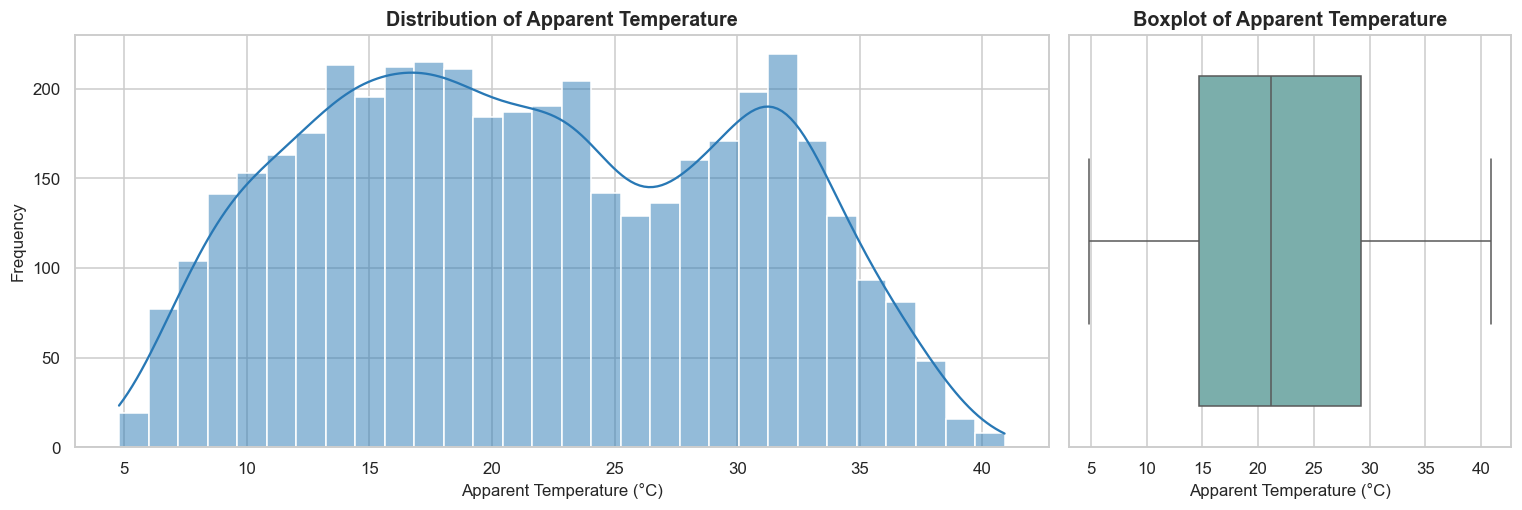

Observation: mean = 21.68 °C, median = 21.10 °C, minimum = 4.80 °C, and maximum = 40.90 °C.


In [48]:
describe_and_plot_continuous(weather, 'apparent_temperature_c', 'Apparent Temperature', '°C')

### 4.3 Relative Humidity

Relative humidity describes the amount of atmospheric moisture relative to saturation. Its distribution is relevant to passenger comfort and the interpretation of monsoon and winter conditions.

,Relative Humidity
count,4344.00
mean,68.20
std,19.92
min,19.00
25%,53.75
50%,71.00
75%,85.00
max,100.00


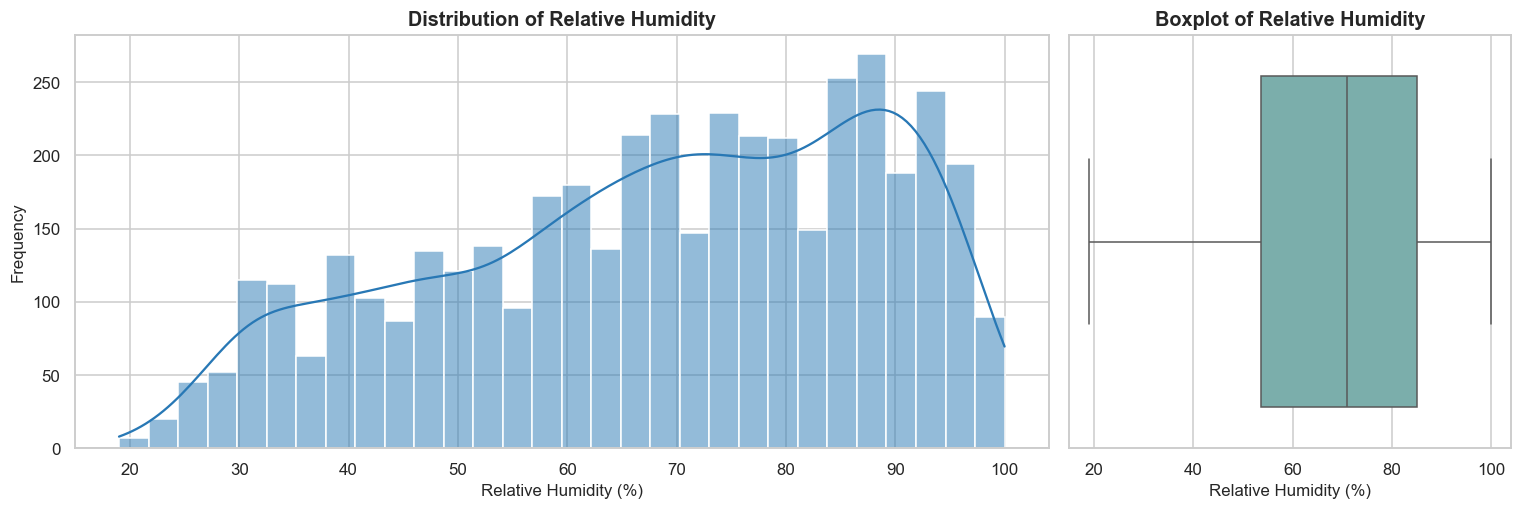

Observation: mean = 68.20 %, median = 71.00 %, minimum = 19.00 %, and maximum = 100.00 %.


In [49]:
describe_and_plot_continuous(weather, 'relative_humidity_2m_pct', 'Relative Humidity', '%')

### 4.4 Precipitation

Hourly precipitation measures total liquid-equivalent precipitation. It is expected to be zero-inflated because rain occurs only during a minority of hours.

,Hourly Precipitation
count,4344.00
mean,0.10
std,0.71
min,0.00
25%,0.00
50%,0.00
75%,0.00
max,13.20


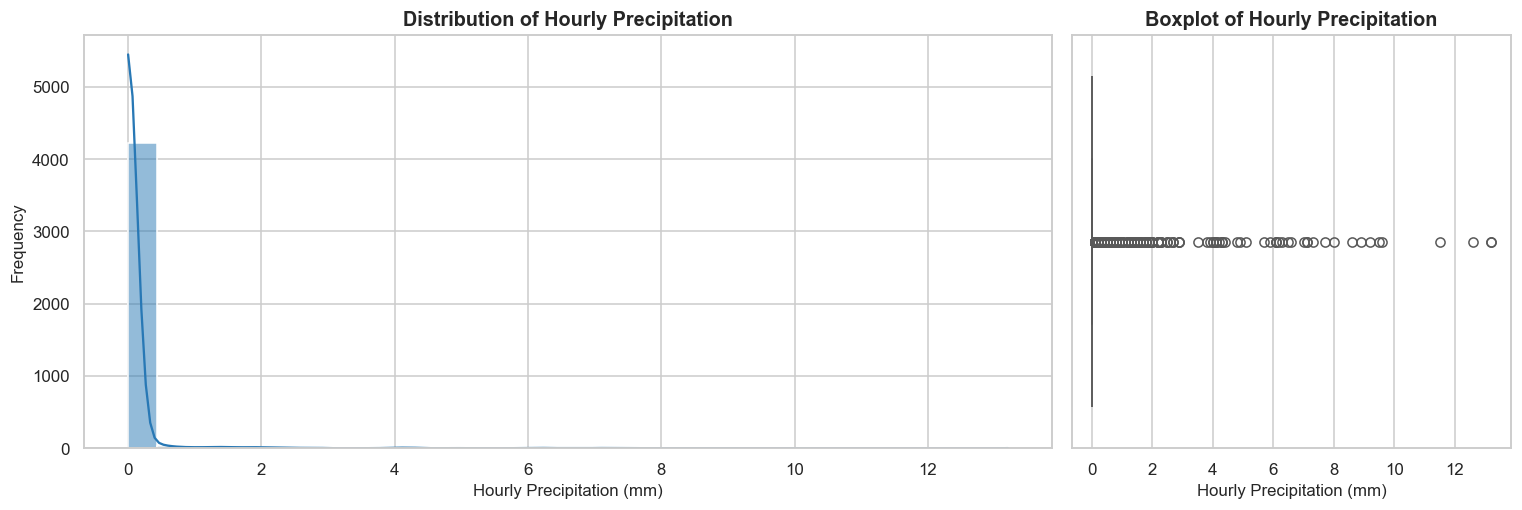

Observation: mean = 0.10 mm, median = 0.00 mm, minimum = 0.00 mm, and maximum = 13.20 mm.


In [50]:
describe_and_plot_continuous(weather, 'precipitation_mm', 'Hourly Precipitation', 'mm')

### 4.5 Rain

Rain is the rainfall component of precipitation. Comparing its distribution with total precipitation provides a direct description of rainfall intensity in the observed period.

,Hourly Rainfall
count,4344.00
mean,0.10
std,0.71
min,0.00
25%,0.00
50%,0.00
75%,0.00
max,13.20


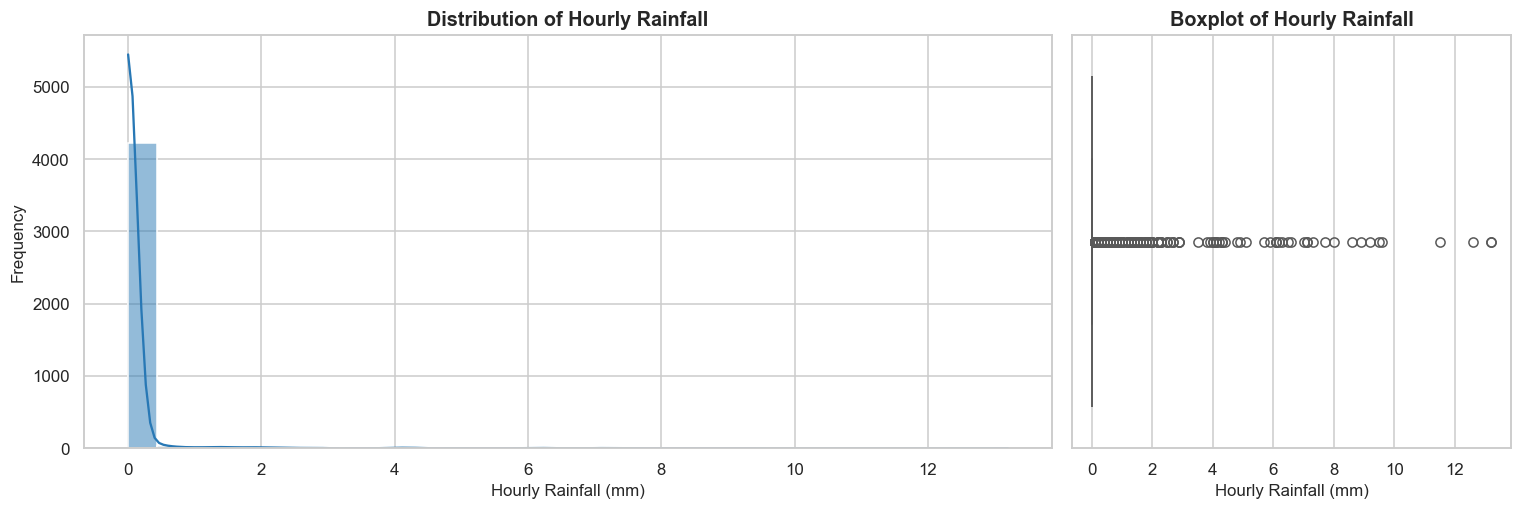

Observation: mean = 0.10 mm, median = 0.00 mm, minimum = 0.00 mm, and maximum = 13.20 mm.


In [51]:
describe_and_plot_continuous(weather, 'rain_mm', 'Hourly Rainfall', 'mm')

### 4.6 Wind Speed

Wind speed at 10 metres describes the strength of near-surface winds and may help distinguish calm, fog-prone conditions from more unsettled weather.

,Wind Speed at 10 m
count,4344.00
mean,6.47
std,3.50
min,0.00
25%,4.00
50%,5.90
75%,8.30
max,24.80


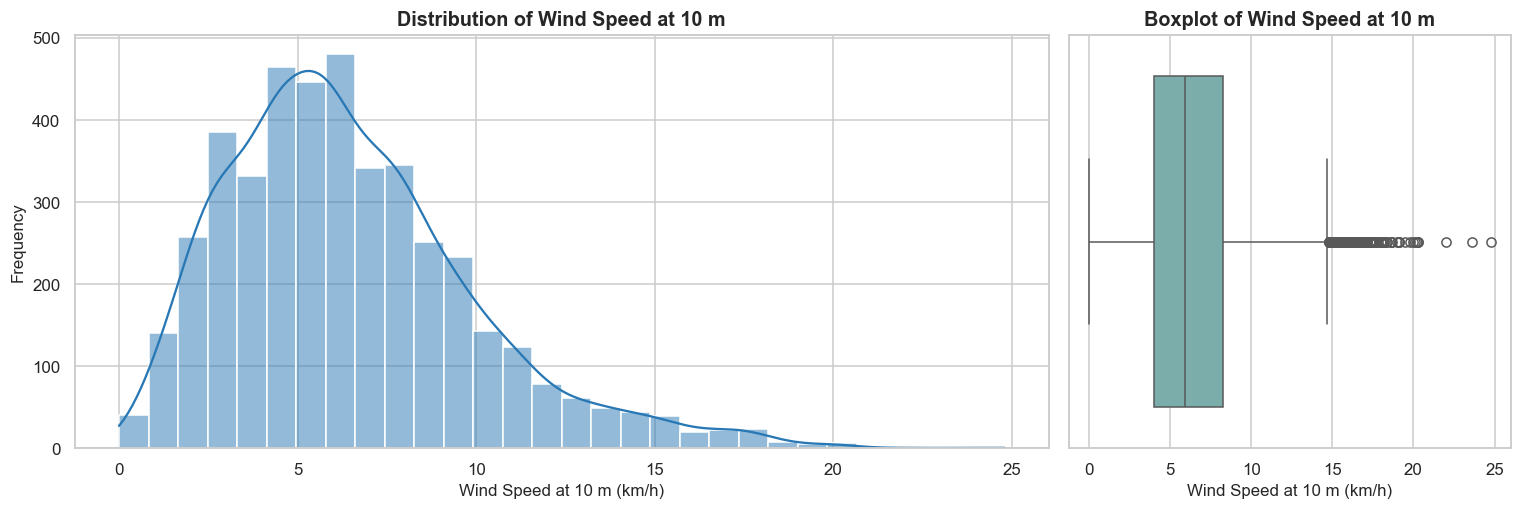

Observation: mean = 6.47 km/h, median = 5.90 km/h, minimum = 0.00 km/h, and maximum = 24.80 km/h.


In [52]:
describe_and_plot_continuous(weather, 'wind_speed_10m_kmh', 'Wind Speed at 10 m', 'km/h')

### 4.7 Cloud Cover

Total cloud cover records the proportion of the sky covered by clouds. This bounded variable helps characterise clear and overcast periods.

,Cloud Cover
count,4344.00
mean,21.38
std,36.49
min,0.00
25%,0.00
50%,0.00
75%,25.00
max,100.00


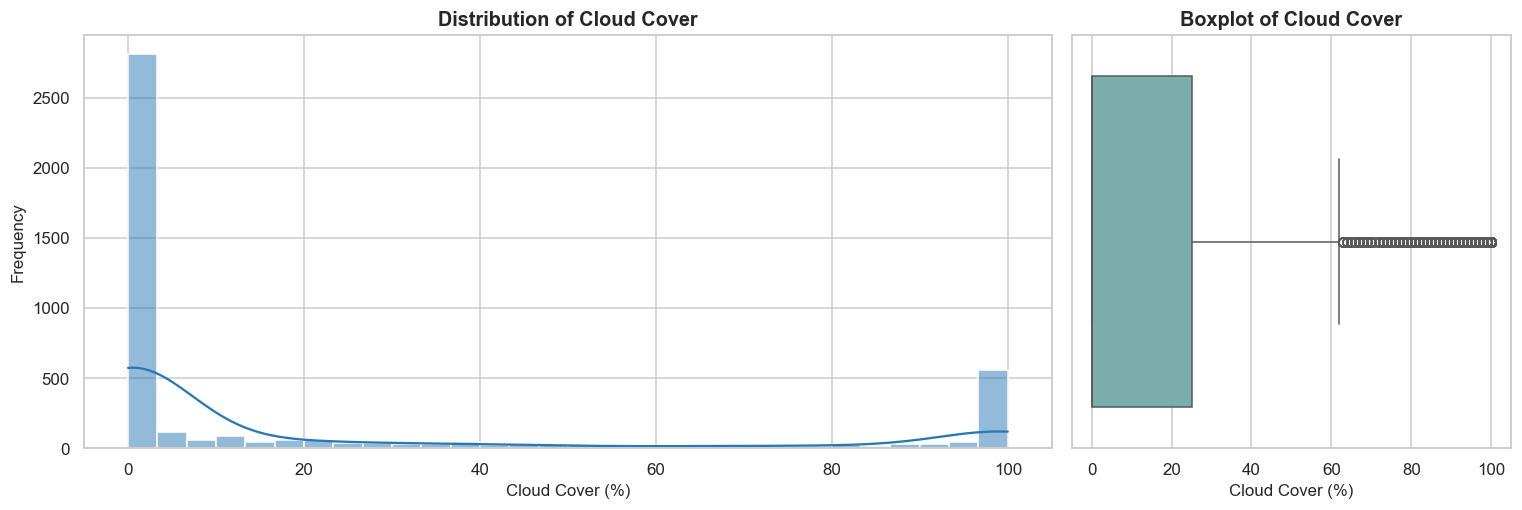

Observation: mean = 21.38 %, median = 0.00 %, minimum = 0.00 %, and maximum = 100.00 %.


In [53]:
describe_and_plot_continuous(weather, 'cloud_cover_pct', 'Cloud Cover', '%')

### 4.8 Visibility

Visibility is an important indicator of conditions such as fog, haze, or heavy precipitation, all of which may affect travel behaviour and operations.

,Visibility
count,4344.00
mean,23436.97
std,2937.96
min,300.00
25%,24140.00
50%,24140.00
75%,24140.00
max,24140.00


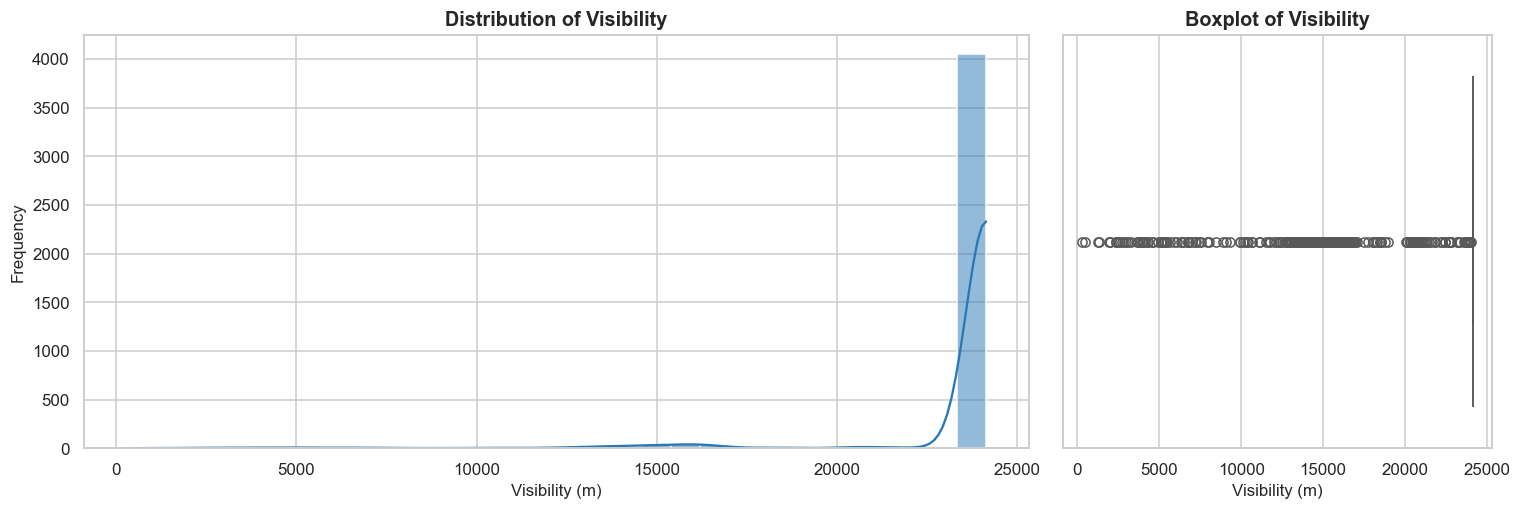

Observation: mean = 23436.97 m, median = 24140.00 m, minimum = 300.00 m, and maximum = 24140.00 m.


In [54]:
describe_and_plot_continuous(weather, 'visibility_m', 'Visibility', 'm')

### 4.9 Surface Pressure

Surface pressure reflects broad atmospheric conditions and is included to describe its range and identify unusual pressure observations.

,Surface Pressure
count,4344.00
mean,987.94
std,4.69
min,973.70
25%,985.50
50%,988.90
75%,991.20
max,998.20


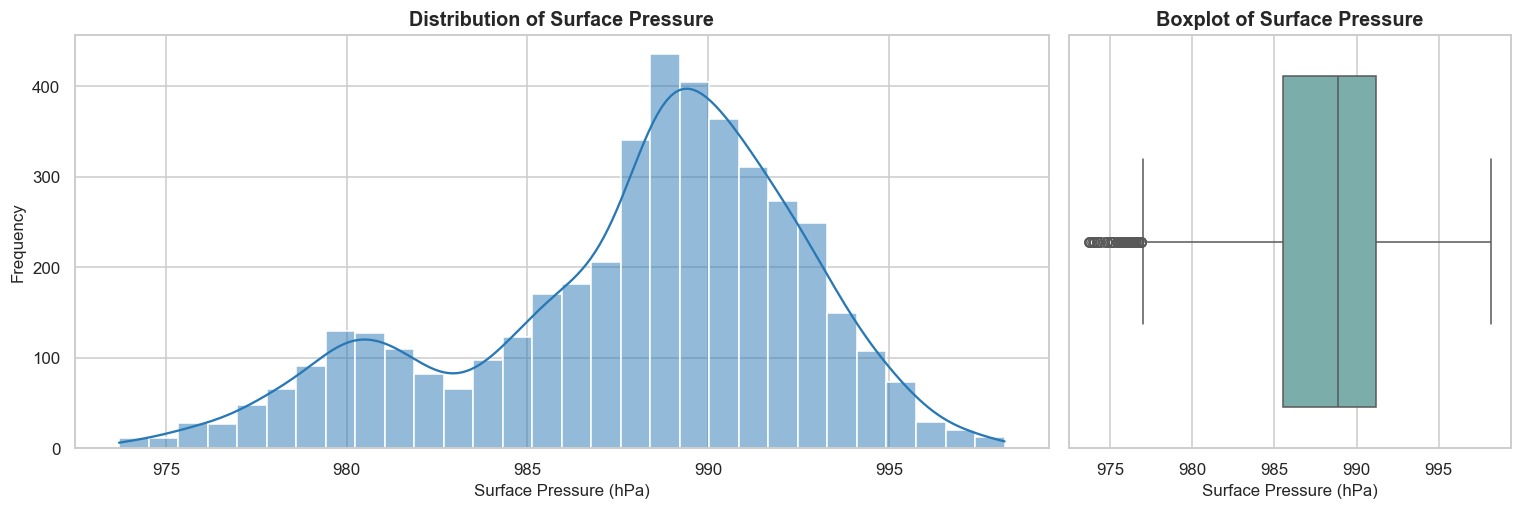

Observation: mean = 987.94 hPa, median = 988.90 hPa, minimum = 973.70 hPa, and maximum = 998.20 hPa.


In [55]:
describe_and_plot_continuous(weather, 'surface_pressure_hpa', 'Surface Pressure', 'hPa')

### 4.10 Weather Code

The WMO weather code is a discrete categorical description of observed conditions. Its frequency analysis is presented separately in Section 7 to avoid treating ordinal category codes as continuous measurements.

In [56]:
print(f'Weather codes present: {sorted(weather["weather_code_wmo"].dropna().unique())}')
print('Observation: weather code is categorical; its count plot and percentage distribution follow in Section 7.')

Weather codes present: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(51), np.int64(53), np.int64(55), np.int64(61), np.int64(63), np.int64(65)]
Observation: weather code is categorical; its count plot and percentage distribution follow in Section 7.


# Dedicated Rainfall Analysis

Rainfall is examined in detail because it is central to later work on hourly Delhi Metro ridership. The classifications below are temporary descriptive constructs only; no forecasting features are created in this notebook.

## 1. Rainfall Distribution

This subsection examines skewness, zero-rainfall observations, and extreme hourly rainfall.

,hourly_rainfall_mm
count,4344.00
mean,0.10
std,0.71
min,0.00
25%,0.00
50%,0.00
75%,0.00
max,13.20


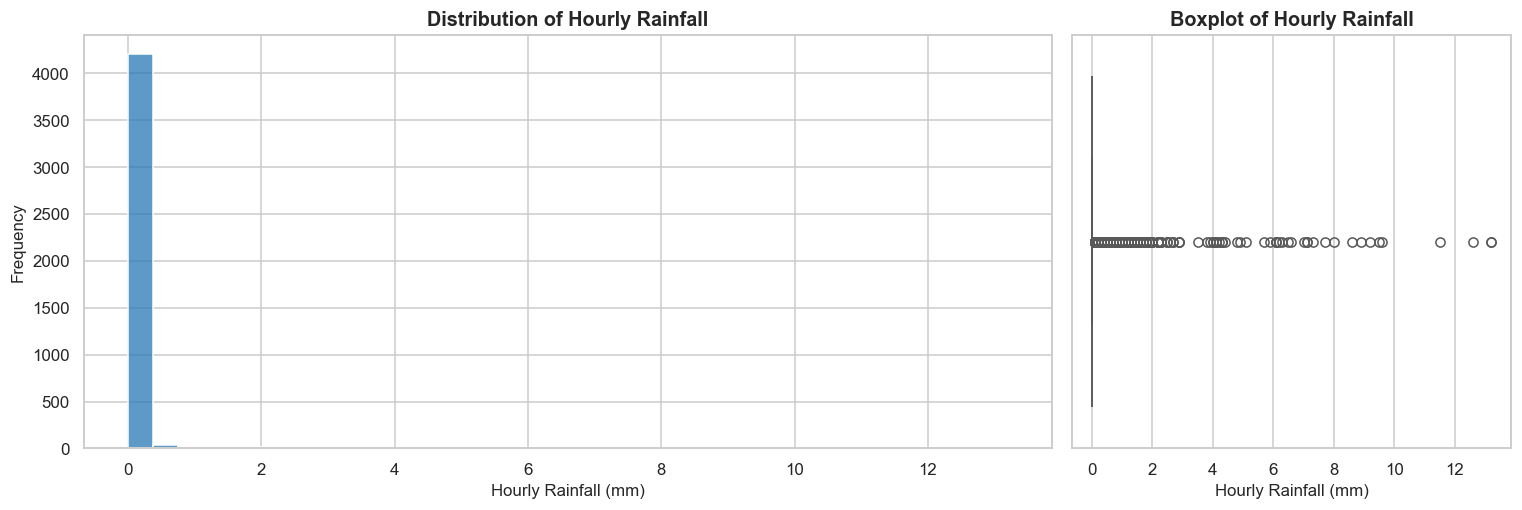

Observation: 93.2% of hours had zero rainfall. The distribution is right-skewed, with a maximum of 13.2 mm.


In [57]:
rain_series = weather['rain_mm'].dropna()
zero_rainfall_pct = rain_series.eq(0).mean() * 100
display(rain_series.describe().to_frame(name='hourly_rainfall_mm'))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [2.2, 1]})
sns.histplot(rain_series, bins=35, color='#2878B5', ax=axes[0]); axes[0].set(title='Distribution of Hourly Rainfall', xlabel='Hourly Rainfall (mm)', ylabel='Frequency')
sns.boxplot(x=rain_series, color='#72B7B2', ax=axes[1]); axes[1].set(title='Boxplot of Hourly Rainfall', xlabel='Hourly Rainfall (mm)')
plt.tight_layout(); plt.show()
print(f'Observation: {zero_rainfall_pct:.1f}% of hours had zero rainfall. The distribution is right-skewed, with a maximum of {rain_series.max():.1f} mm.')

## 2. Rainy Hours versus Dry Hours

An hour is rainy when rainfall exceeds zero.

## 3. Rainfall Intensity Analysis

Hourly rainfall is classified as No Rain (0 mm), Light Rain (>0–2.5 mm), Moderate Rain (>2.5–7.6 mm), and Heavy Rain (>7.6 mm).

,hours,percentage
Rainy,297,6.84
Dry,4047,93.16


,hours,percentage
rain_mm,,
No Rain,4047,93.16
Light Rain,251,5.78
Moderate Rain,35,0.81
Heavy Rain,11,0.25


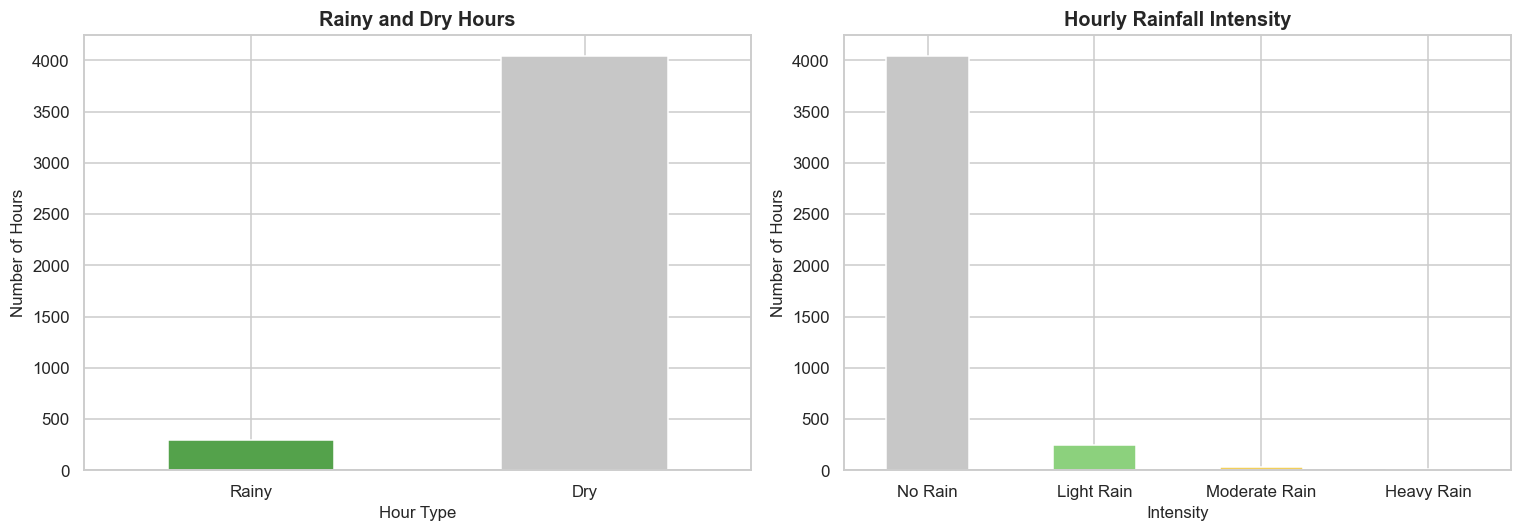

Observation: 6.84% of hours were rainy. Heavy rain occurred in 11 hours (0.25%).


In [58]:
rain_status = pd.Series(np.where(weather['rain_mm'].gt(0), 'Rainy', 'Dry'))
rainy_dry_summary = rain_status.value_counts().reindex(['Rainy', 'Dry']).to_frame('hours')
rainy_dry_summary['percentage'] = (rainy_dry_summary['hours'] / len(weather) * 100).round(2)
intensity_labels = ['No Rain', 'Light Rain', 'Moderate Rain', 'Heavy Rain']
rainfall_intensity = pd.cut(weather['rain_mm'], [-0.001, 0, 2.5, 7.6, np.inf], labels=intensity_labels)
intensity_summary = rainfall_intensity.value_counts().reindex(intensity_labels).to_frame('hours')
intensity_summary['percentage'] = (intensity_summary['hours'] / len(weather) * 100).round(2)
display(rainy_dry_summary); display(intensity_summary)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
rainy_dry_summary['hours'].plot(kind='bar', ax=axes[0], color=['#54A24B', '#C7C7C7'], rot=0); axes[0].set(title='Rainy and Dry Hours', xlabel='Hour Type', ylabel='Number of Hours')
intensity_summary['hours'].plot(kind='bar', ax=axes[1], color=['#C7C7C7', '#8CD17D', '#F2CF5B', '#E45756'], rot=0); axes[1].set(title='Hourly Rainfall Intensity', xlabel='Intensity', ylabel='Number of Hours')
plt.tight_layout(); plt.show()
print(f'Observation: {rainy_dry_summary.loc["Rainy", "percentage"]:.2f}% of hours were rainy. Heavy rain occurred in {intensity_summary.loc["Heavy Rain", "hours"]:,} hours ({intensity_summary.loc["Heavy Rain", "percentage"]:.2f}%).')

## 4. Monthly Rainfall Characteristics

Monthly totals, mean rainfall, rainy hours, and heavy-rain hours show seasonal concentration.

## 5. Hourly Rainfall Characteristics

Hourly patterns identify whether rainfall overlaps with morning (07:00–10:00) or evening (17:00–20:00) commuting periods.

,total_rainfall_mm,average_hourly_rainfall_mm,rainy_hours,heavy_rain_hours
month,,,,
2024-09,337.00,0.47,214,11
2024-10,0.00,0.00,0,0
2024-11,0.00,0.00,0,0
2024-12,38.50,0.05,30,0
2025-01,17.60,0.02,26,0
2025-02,20.70,0.03,27,0


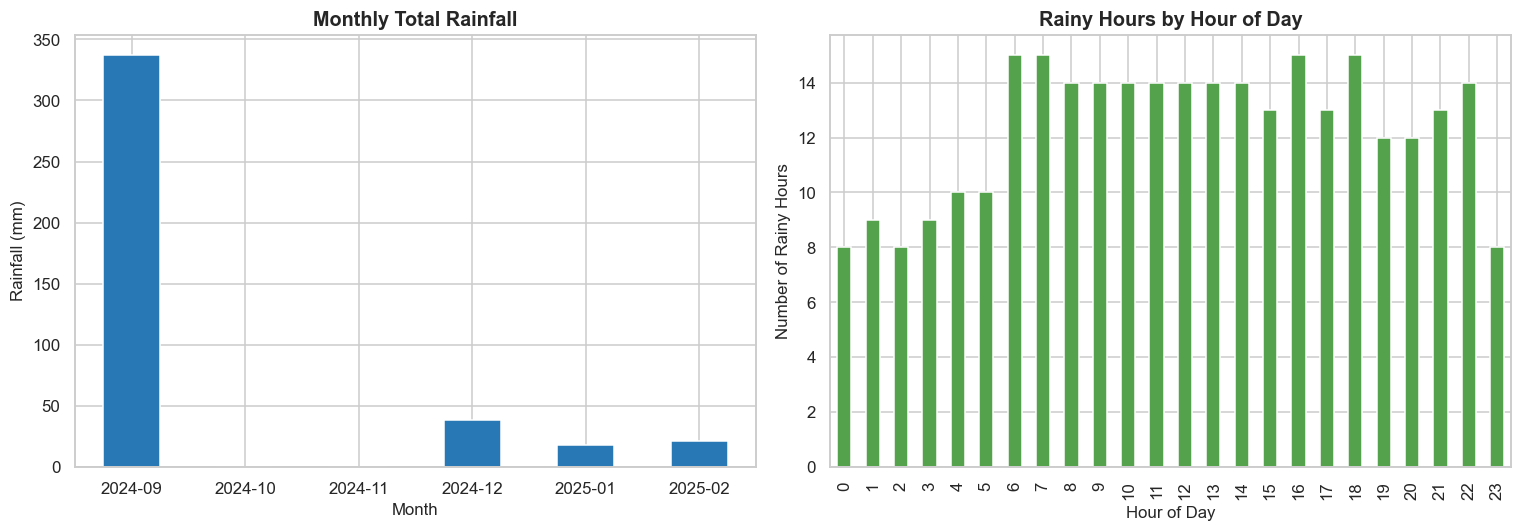

Observation: 2024-09 had the highest monthly rainfall. Rainfall was most common at 06:00; morning and evening commuting periods contained 57 and 52 rainy observations, respectively.


In [59]:
rainfall_monthly = weather.assign(month=weather['time'].dt.to_period('M')).groupby('month').agg(total_rainfall_mm=('rain_mm', 'sum'), average_hourly_rainfall_mm=('rain_mm', 'mean'), rainy_hours=('rain_mm', lambda x: x.gt(0).sum()), heavy_rain_hours=('rain_mm', lambda x: x.gt(7.6).sum()))
rainfall_hourly = weather.assign(hour=weather['time'].dt.hour).groupby('hour').agg(average_rainfall_mm=('rain_mm', 'mean'), rainy_hours=('rain_mm', lambda x: x.gt(0).sum()))
display(rainfall_monthly)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
rainfall_monthly['total_rainfall_mm'].plot(kind='bar', ax=axes[0], color='#2878B5', rot=0); axes[0].set(title='Monthly Total Rainfall', xlabel='Month', ylabel='Rainfall (mm)')
rainfall_hourly['rainy_hours'].plot(kind='bar', ax=axes[1], color='#54A24B'); axes[1].set(title='Rainy Hours by Hour of Day', xlabel='Hour of Day', ylabel='Number of Rainy Hours')
plt.tight_layout(); plt.show()
peak_rain_hour = rainfall_hourly['rainy_hours'].idxmax()
print(f'Observation: {rainfall_monthly["total_rainfall_mm"].idxmax()} had the highest monthly rainfall. Rainfall was most common at {peak_rain_hour:02d}:00; morning and evening commuting periods contained {rainfall_hourly.loc[7:10, "rainy_hours"].sum():,} and {rainfall_hourly.loc[17:20, "rainy_hours"].sum():,} rainy observations, respectively.')

## 6. Rainfall Event Analysis

A rainfall event is one or more consecutive hours with rainfall greater than zero.

## 7. Dry Spell Analysis

A dry spell is one or more consecutive hours with no recorded rainfall.

,rainfall_event_hours
count,71.00
mean,4.18
std,5.59
min,1.00
25%,1.00
50%,2.00
75%,4.00
max,33.00


,dry_spell_hours
count,72.00
mean,56.21
std,208.13
min,1.00
25%,2.00
50%,5.00
75%,18.25
max,1685.00


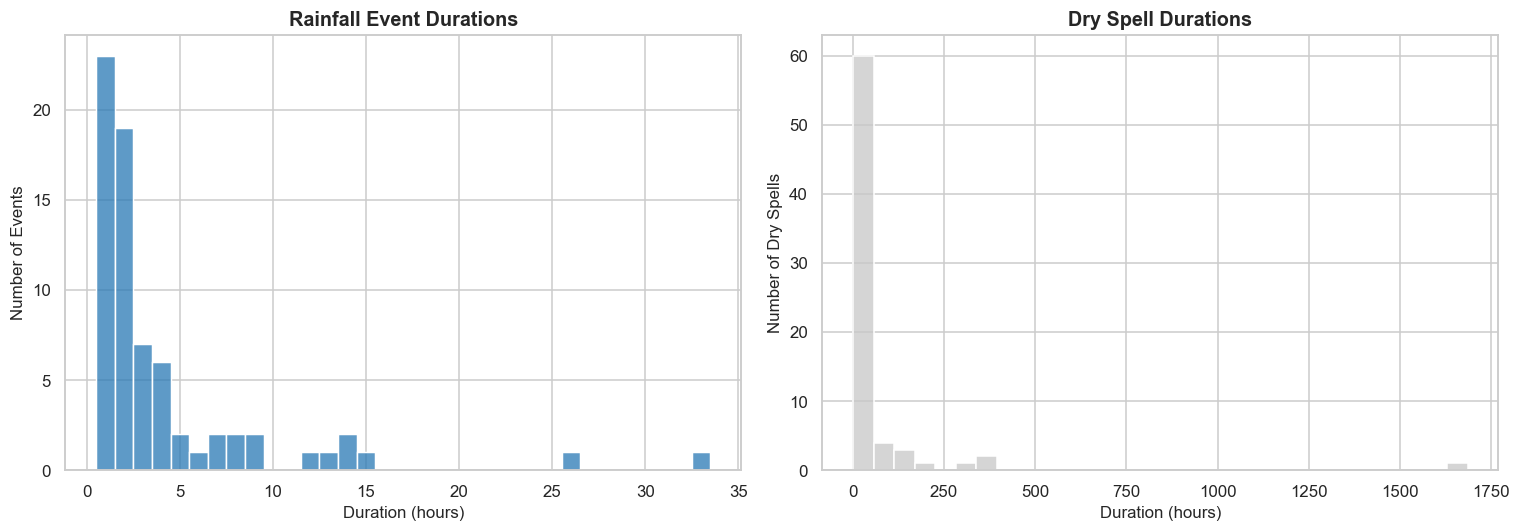

Observation: 71 rainfall events were identified; their median duration was 2 hours and the longest lasted 33 hours. The longest dry spell lasted 1685 hours.


In [60]:
rain_flag = weather['rain_mm'].gt(0); rain_group = rain_flag.ne(rain_flag.shift()).cumsum()
rainfall_events = weather.loc[rain_flag].groupby(rain_group[rain_flag]).agg(start_time=('time', 'min'), end_time=('time', 'max'), duration_hours=('time', 'size'), total_rainfall_mm=('rain_mm', 'sum'))
dry_flag = weather['rain_mm'].eq(0); dry_group = dry_flag.ne(dry_flag.shift()).cumsum()
dry_spells = weather.loc[dry_flag].groupby(dry_group[dry_flag]).agg(start_time=('time', 'min'), end_time=('time', 'max'), duration_hours=('time', 'size'))
display(rainfall_events['duration_hours'].describe().to_frame(name='rainfall_event_hours')); display(dry_spells['duration_hours'].describe().to_frame(name='dry_spell_hours'))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(rainfall_events['duration_hours'], discrete=True, color='#2878B5', ax=axes[0]); axes[0].set(title='Rainfall Event Durations', xlabel='Duration (hours)', ylabel='Number of Events')
sns.histplot(dry_spells['duration_hours'], bins=30, color='#C7C7C7', ax=axes[1]); axes[1].set(title='Dry Spell Durations', xlabel='Duration (hours)', ylabel='Number of Dry Spells')
plt.tight_layout(); plt.show()
print(f'Observation: {len(rainfall_events):,} rainfall events were identified; their median duration was {rainfall_events["duration_hours"].median():.0f} hours and the longest lasted {rainfall_events["duration_hours"].max():.0f} hours. The longest dry spell lasted {dry_spells["duration_hours"].max():.0f} hours.')

## 8. Rainfall Timeline

A daily timeline highlights rainfall clustering and prolonged dry periods.

## 9. Rainfall and Weather Codes

Observed WMO codes are mapped to plain-language conditions to identify drizzle and rain categories.

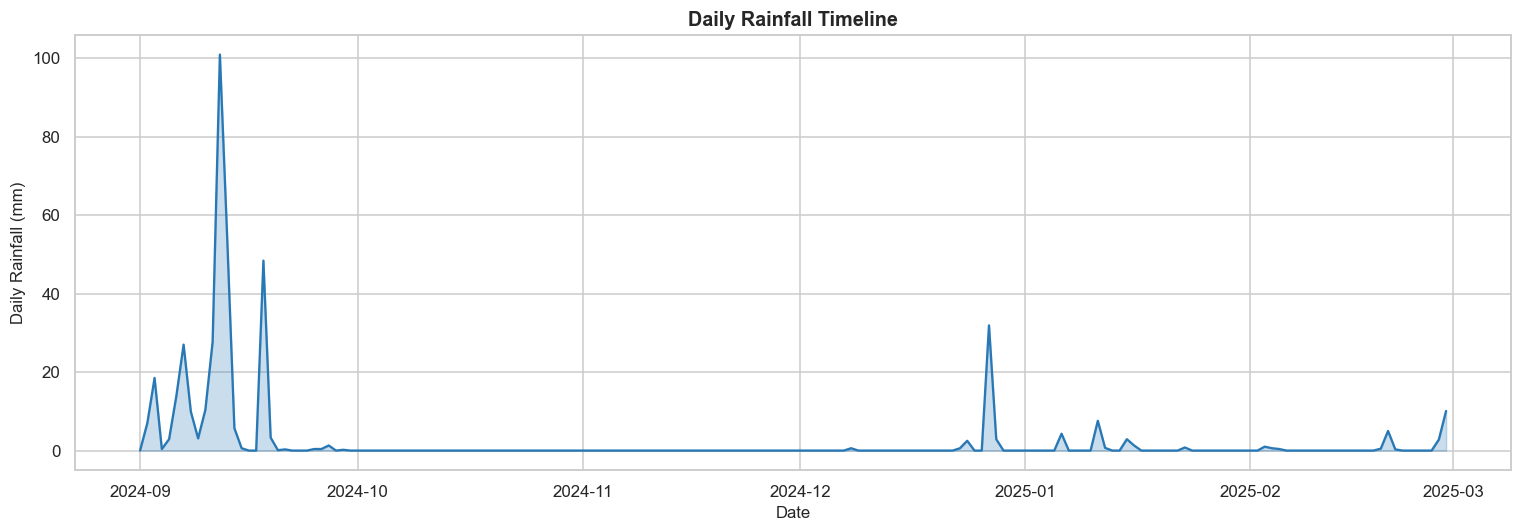

,description,frequency,percentage
weather_code_wmo,,,
0,Clear sky,3171,73.00
1,Mainly clear,265,6.10
2,Partly cloudy,115,2.65
3,Overcast,496,11.42
51,Light drizzle,171,3.94
53,Moderate drizzle,29,0.67
55,Dense drizzle,11,0.25
61,Slight rain,38,0.87
63,Moderate rain,37,0.85


Observation: daily rainfall peaked at 100.9 mm on 12 September 2024. The dominant WMO condition was Clear sky; rain-related codes observed were [51, 53, 55, 61, 63, 65].


In [61]:
daily_rainfall = weather.set_index('time')['rain_mm'].resample('D').sum()
plt.figure(figsize=(14, 5)); plt.plot(daily_rainfall.index, daily_rainfall.values, color='#2878B5'); plt.fill_between(daily_rainfall.index, daily_rainfall.values, color='#2878B5', alpha=0.25); plt.title('Daily Rainfall Timeline'); plt.xlabel('Date'); plt.ylabel('Daily Rainfall (mm)'); plt.tight_layout(); plt.show()
wmo_descriptions = {0:'Clear sky', 1:'Mainly clear', 2:'Partly cloudy', 3:'Overcast', 51:'Light drizzle', 53:'Moderate drizzle', 55:'Dense drizzle', 61:'Slight rain', 63:'Moderate rain', 65:'Heavy rain'}
rainfall_code_summary = weather['weather_code_wmo'].value_counts().sort_index().rename_axis('weather_code_wmo').to_frame('frequency')
rainfall_code_summary['description'] = rainfall_code_summary.index.map(wmo_descriptions).fillna('Other WMO condition'); rainfall_code_summary['percentage'] = (rainfall_code_summary['frequency'] / len(weather) * 100).round(2)
display(rainfall_code_summary[['description', 'frequency', 'percentage']])
rain_codes = rainfall_code_summary.index[rainfall_code_summary['description'].str.contains('drizzle|rain', case=False)].tolist()
print(f'Observation: daily rainfall peaked at {daily_rainfall.max():.1f} mm on {daily_rainfall.idxmax():%d %B %Y}. The dominant WMO condition was {rainfall_code_summary.loc[rainfall_code_summary["frequency"].idxmax(), "description"]}; rain-related codes observed were {rain_codes}.')

## 10. Rainfall Summary

The following markdown-ready synthesis is suitable for inclusion in the research report after execution.

In [62]:
print(f"### Dedicated Rainfall Analysis Summary\n\nRainfall occurred in **{rainy_dry_summary.loc['Rainy', 'hours']:,} of {len(weather):,} hours** ({rainy_dry_summary.loc['Rainy', 'percentage']:.2f}%), with a strongly right-skewed hourly distribution. Heavy rain accounted for **{intensity_summary.loc['Heavy Rain', 'hours']:,} hours**. Rainfall was most concentrated in **{rainfall_monthly['total_rainfall_mm'].idxmax()}** and most commonly observed at **{peak_rain_hour:02d}:00**.\n\nThe data contain **{len(rainfall_events):,} rainfall events**, with a median duration of **{rainfall_events['duration_hours'].median():.0f} hours** and a longest duration of **{rainfall_events['duration_hours'].max():.0f} hours**. Later work may consider rainfall occurrence, intensity, persistence, and alignment with commuting periods when examining weather and metro ridership; this notebook does not create or test those features.")

### Dedicated Rainfall Analysis Summary

Rainfall occurred in **297 of 4,344 hours** (6.84%), with a strongly right-skewed hourly distribution. Heavy rain accounted for **11 hours**. Rainfall was most concentrated in **2024-09** and most commonly observed at **06:00**.

The data contain **71 rainfall events**, with a median duration of **2 hours** and a longest duration of **33 hours**. Later work may consider rainfall occurrence, intensity, persistence, and alignment with commuting periods when examining weather and metro ridership; this notebook does not create or test those features.


## 5. Time-Based Weather Analysis

Hourly and monthly aggregation reveals recurrent within-day cycles and broader seasonal changes. These descriptive patterns are especially relevant to later hourly ridership analysis, while remaining separate from modelling.

In [63]:
weather_time = weather.copy()
weather_time['hour'] = weather_time['time'].dt.hour
weather_time['month'] = weather_time['time'].dt.to_period('M')
print('Hour and month labels created solely for descriptive aggregation in this EDA notebook.')

Hour and month labels created solely for descriptive aggregation in this EDA notebook.


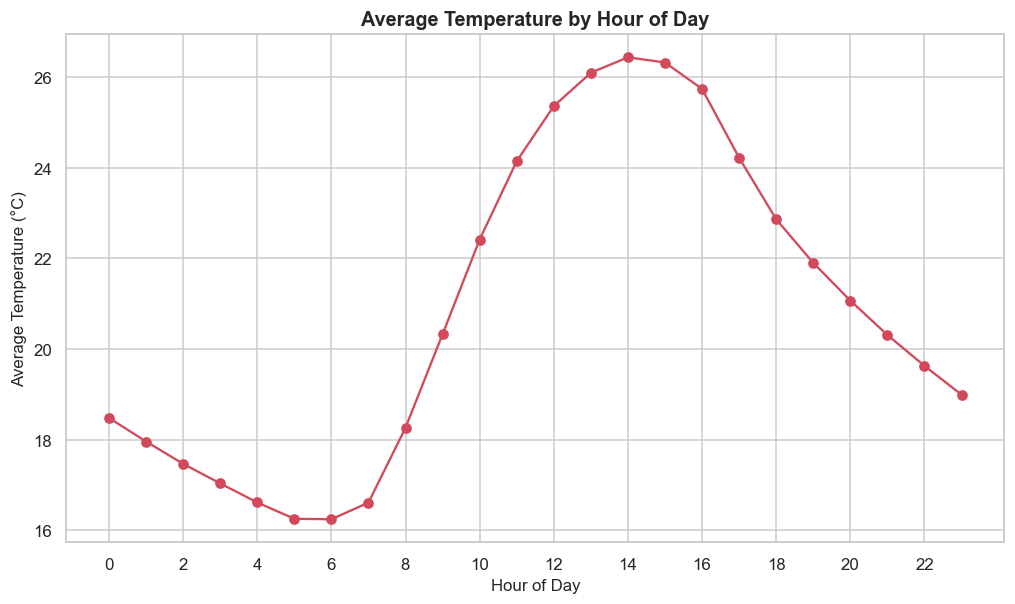

Observation: average temperature is lowest at 06:00 and highest at 14:00.


In [64]:
hourly_temperature = weather_time.groupby('hour')['temperature_2m_c'].mean()
ax = hourly_temperature.plot(marker='o', color='#D1495B')
ax.set(title='Average Temperature by Hour of Day', xlabel='Hour of Day', ylabel='Average Temperature (°C)', xticks=range(0, 24, 2))
plt.show()
print(f'Observation: average temperature is lowest at {hourly_temperature.idxmin():02d}:00 and highest at {hourly_temperature.idxmax():02d}:00.')

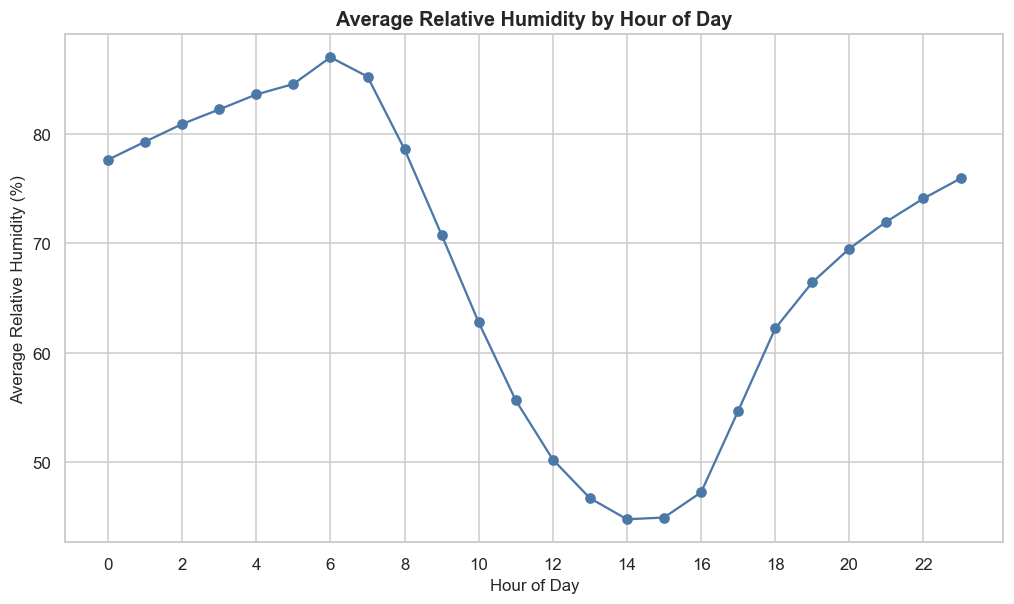

Observation: average humidity is lowest at 14:00 and highest at 06:00.


In [65]:
hourly_humidity = weather_time.groupby('hour')['relative_humidity_2m_pct'].mean()
ax = hourly_humidity.plot(marker='o', color='#4C78A8')
ax.set(title='Average Relative Humidity by Hour of Day', xlabel='Hour of Day', ylabel='Average Relative Humidity (%)', xticks=range(0, 24, 2))
plt.show()
print(f'Observation: average humidity is lowest at {hourly_humidity.idxmin():02d}:00 and highest at {hourly_humidity.idxmax():02d}:00.')

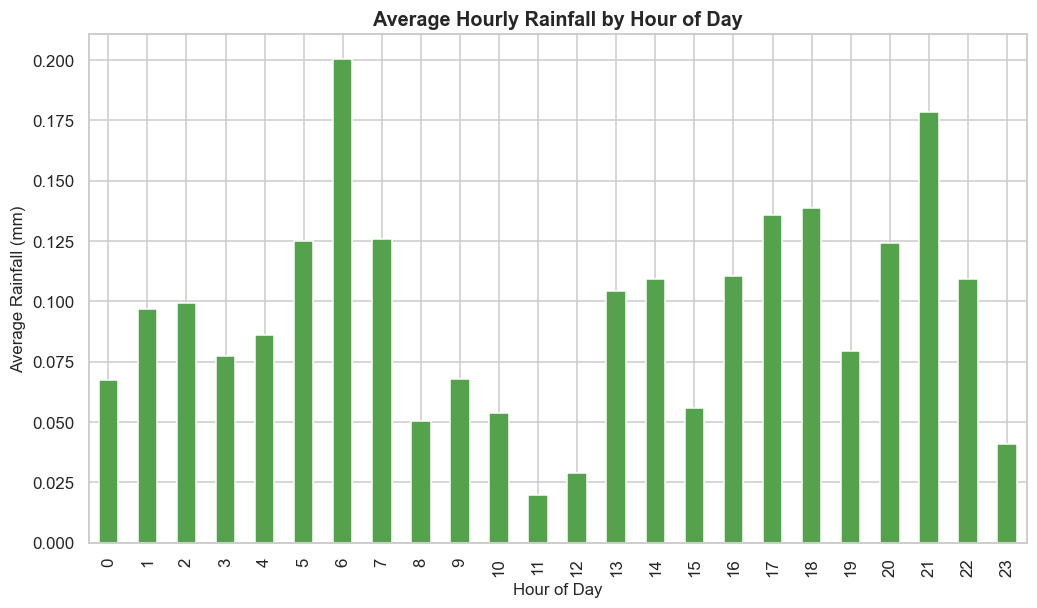

Observation: mean hourly rainfall is greatest at 06:00 (0.20 mm).


In [66]:
hourly_rainfall = weather_time.groupby('hour')['rain_mm'].mean()
ax = hourly_rainfall.plot(kind='bar', color='#54A24B')
ax.set(title='Average Hourly Rainfall by Hour of Day', xlabel='Hour of Day', ylabel='Average Rainfall (mm)')
plt.show()
print(f'Observation: mean hourly rainfall is greatest at {hourly_rainfall.idxmax():02d}:00 ({hourly_rainfall.max():.2f} mm).')

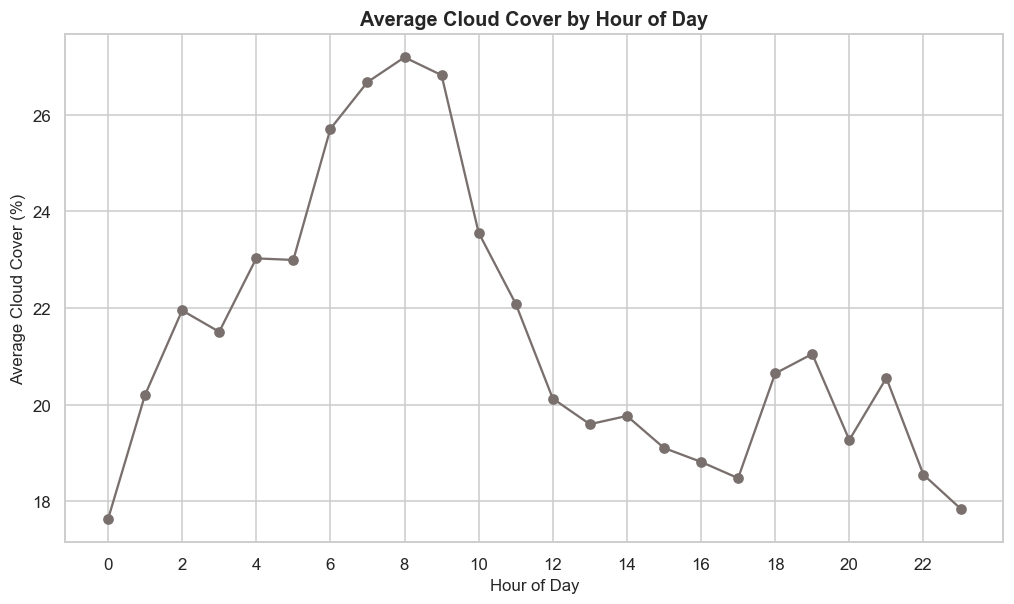

Observation: average cloud cover is greatest at 08:00.


In [67]:
hourly_cloud = weather_time.groupby('hour')['cloud_cover_pct'].mean()
ax = hourly_cloud.plot(marker='o', color='#79706E')
ax.set(title='Average Cloud Cover by Hour of Day', xlabel='Hour of Day', ylabel='Average Cloud Cover (%)', xticks=range(0, 24, 2))
plt.show()
print(f'Observation: average cloud cover is greatest at {hourly_cloud.idxmax():02d}:00.')

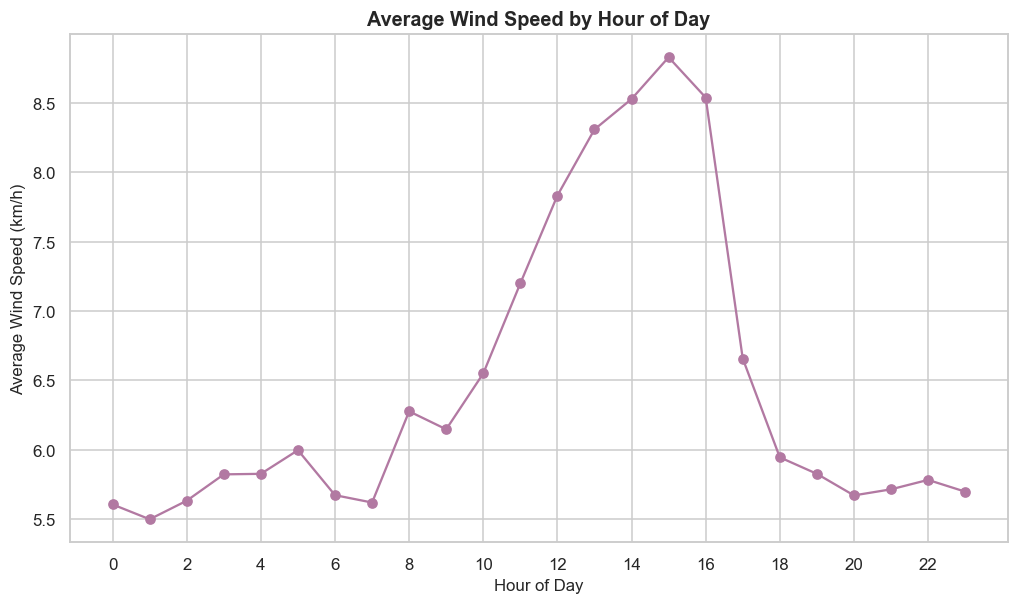

Observation: average wind speed is lowest at 01:00 and highest at 15:00.


In [68]:
hourly_wind = weather_time.groupby('hour')['wind_speed_10m_kmh'].mean()
ax = hourly_wind.plot(marker='o', color='#B279A2')
ax.set(title='Average Wind Speed by Hour of Day', xlabel='Hour of Day', ylabel='Average Wind Speed (km/h)', xticks=range(0, 24, 2))
plt.show()
print(f'Observation: average wind speed is lowest at {hourly_wind.idxmin():02d}:00 and highest at {hourly_wind.idxmax():02d}:00.')

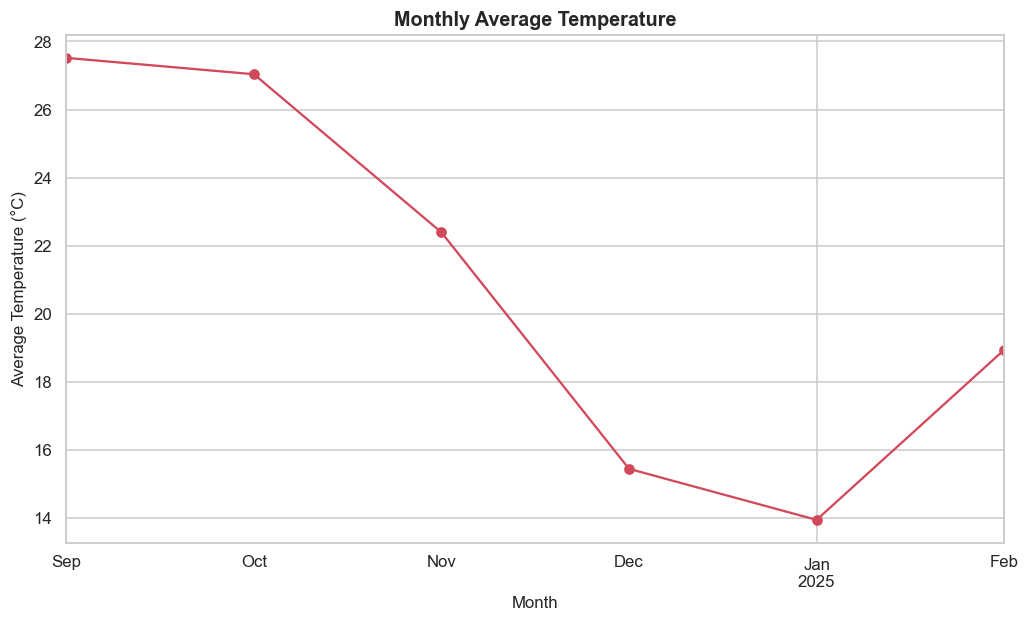

Observation: the warmest month is 2024-09 and the coolest month is 2025-01.


In [69]:
monthly_temperature = weather_time.groupby('month')['temperature_2m_c'].mean()
ax = monthly_temperature.plot(marker='o', color='#D1495B')
ax.set(title='Monthly Average Temperature', xlabel='Month', ylabel='Average Temperature (°C)')
plt.show()
print(f'Observation: the warmest month is {monthly_temperature.idxmax()} and the coolest month is {monthly_temperature.idxmin()}.')

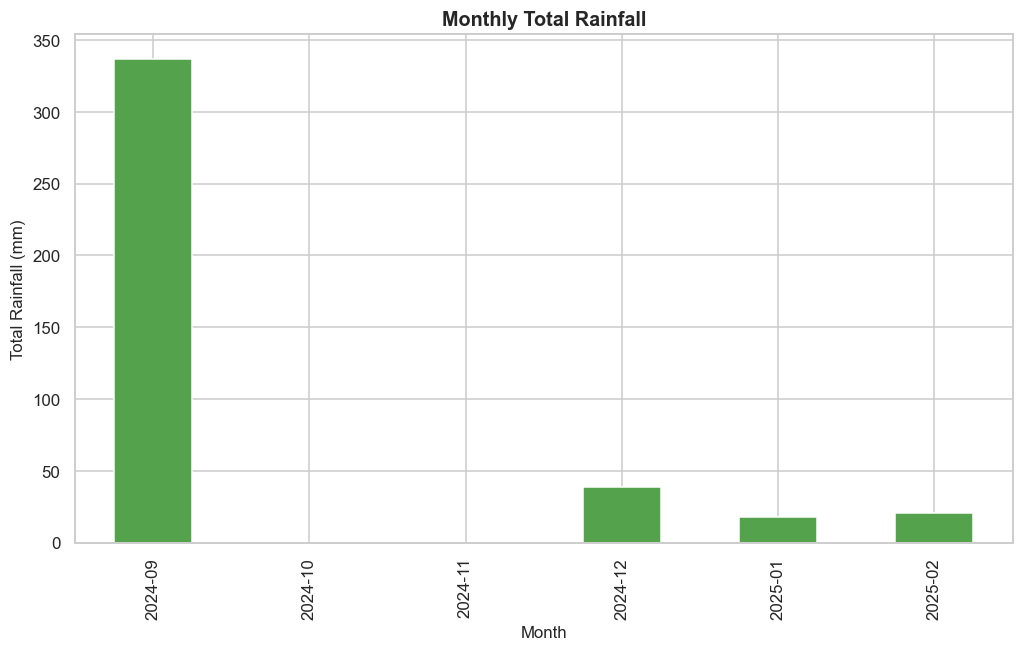

Observation: 2024-09 records the highest monthly rainfall (337.0 mm).


In [70]:
monthly_rainfall = weather_time.groupby('month')['rain_mm'].sum()
ax = monthly_rainfall.plot(kind='bar', color='#54A24B')
ax.set(title='Monthly Total Rainfall', xlabel='Month', ylabel='Total Rainfall (mm)')
plt.show()
print(f'Observation: {monthly_rainfall.idxmax()} records the highest monthly rainfall ({monthly_rainfall.max():.1f} mm).')

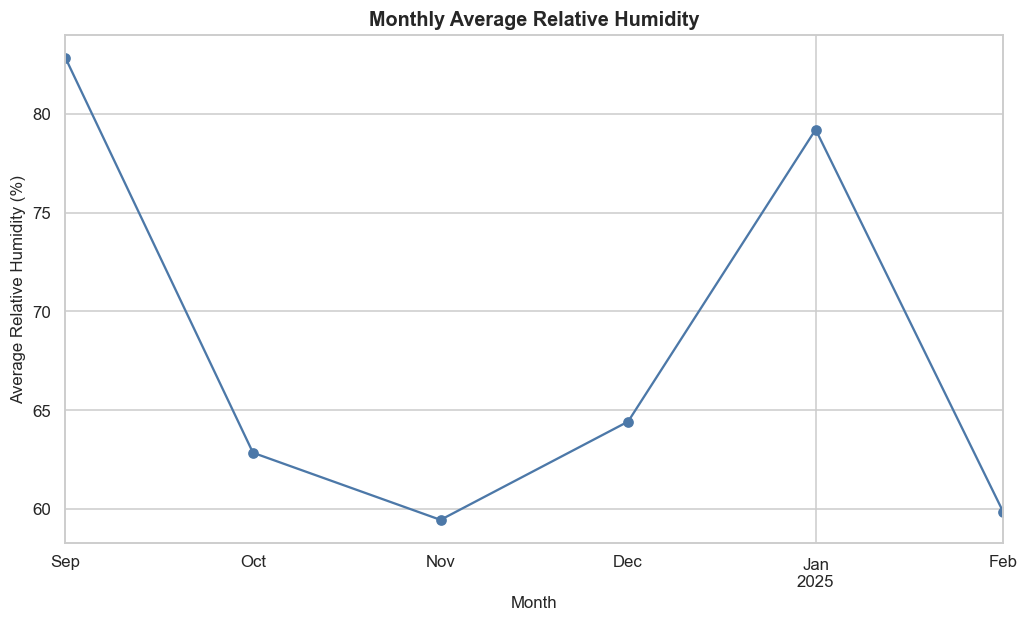

Observation: average humidity is highest in 2024-09 and lowest in 2024-11.


In [71]:
monthly_humidity = weather_time.groupby('month')['relative_humidity_2m_pct'].mean()
ax = monthly_humidity.plot(marker='o', color='#4C78A8')
ax.set(title='Monthly Average Relative Humidity', xlabel='Month', ylabel='Average Relative Humidity (%)')
plt.show()
print(f'Observation: average humidity is highest in {monthly_humidity.idxmax()} and lowest in {monthly_humidity.idxmin()}.')

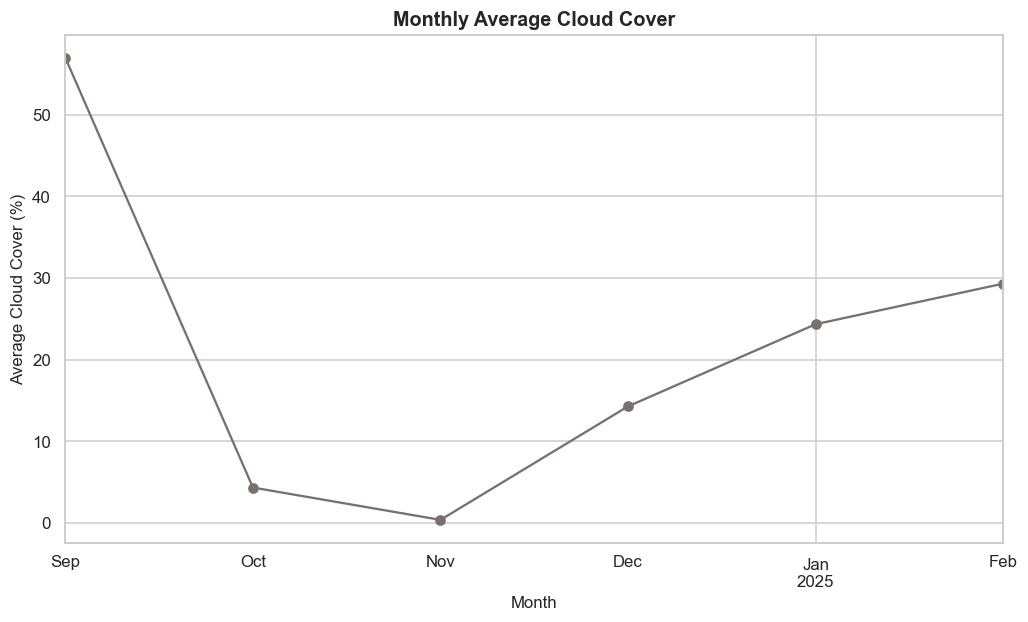

Observation: average cloud cover is highest in 2024-09 and lowest in 2024-11.


In [72]:
monthly_cloud = weather_time.groupby('month')['cloud_cover_pct'].mean()
ax = monthly_cloud.plot(marker='o', color='#79706E')
ax.set(title='Monthly Average Cloud Cover', xlabel='Month', ylabel='Average Cloud Cover (%)')
plt.show()
print(f'Observation: average cloud cover is highest in {monthly_cloud.idxmax()} and lowest in {monthly_cloud.idxmin()}.')

## 6. Weather Variable Relationships

This section describes associations among continuous weather variables. Correlation and selected scatterplots help identify measures that move together, which is useful context for interpreting meteorological conditions that may later be considered alongside ridership. Correlation is descriptive and does not establish causation.

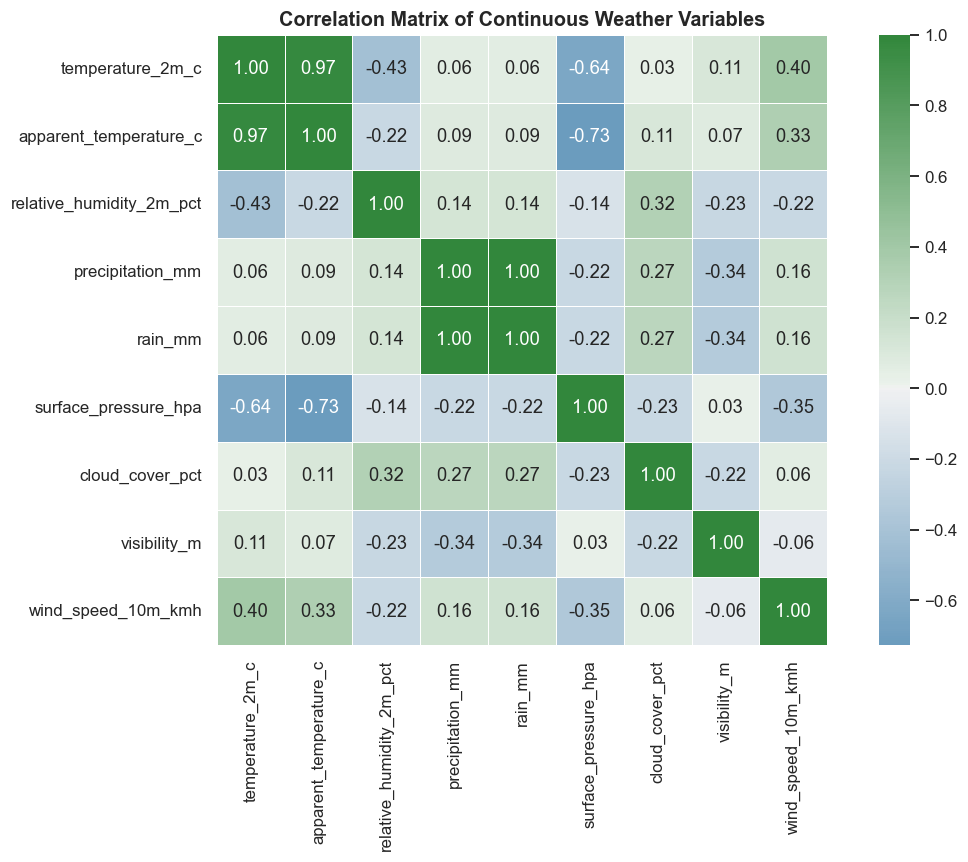

Observation: the strongest absolute pairwise correlation is between precipitation_mm and rain_mm (1.00).


In [73]:
relationship_columns = [
    'temperature_2m_c', 'apparent_temperature_c', 'relative_humidity_2m_pct',
    'precipitation_mm', 'rain_mm', 'surface_pressure_hpa', 'cloud_cover_pct',
    'visibility_m', 'wind_speed_10m_kmh'
]
correlation_matrix = weather[relationship_columns].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap=sns.diverging_palette(240, 130, s=80, l=50, as_cmap=True), center=0, square=True, linewidths=0.5)
plt.title('Correlation Matrix of Continuous Weather Variables')
plt.tight_layout()
plt.show()

strongest_pair = correlation_matrix.where(~np.eye(len(correlation_matrix), dtype=bool)).stack().abs().idxmax()
strongest_value = correlation_matrix.loc[strongest_pair[0], strongest_pair[1]]
print(f'Observation: the strongest absolute pairwise correlation is between {strongest_pair[0]} and {strongest_pair[1]} ({strongest_value:.2f}).')

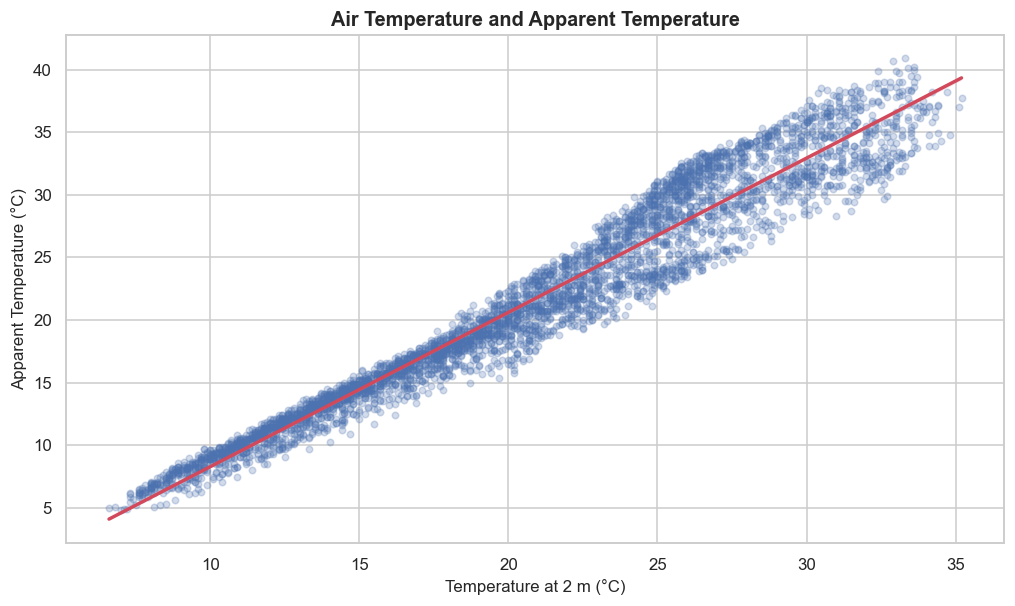

Observation: temperature and apparent temperature have a correlation of 0.97.


In [74]:
sns.regplot(data=weather, x='temperature_2m_c', y='apparent_temperature_c', scatter_kws={'alpha': 0.25, 's': 18}, line_kws={'color': '#D1495B'})
plt.title('Air Temperature and Apparent Temperature')
plt.xlabel('Temperature at 2 m (°C)')
plt.ylabel('Apparent Temperature (°C)')
plt.show()
print(f'Observation: temperature and apparent temperature have a correlation of {correlation_matrix.loc["temperature_2m_c", "apparent_temperature_c"]:.2f}.')

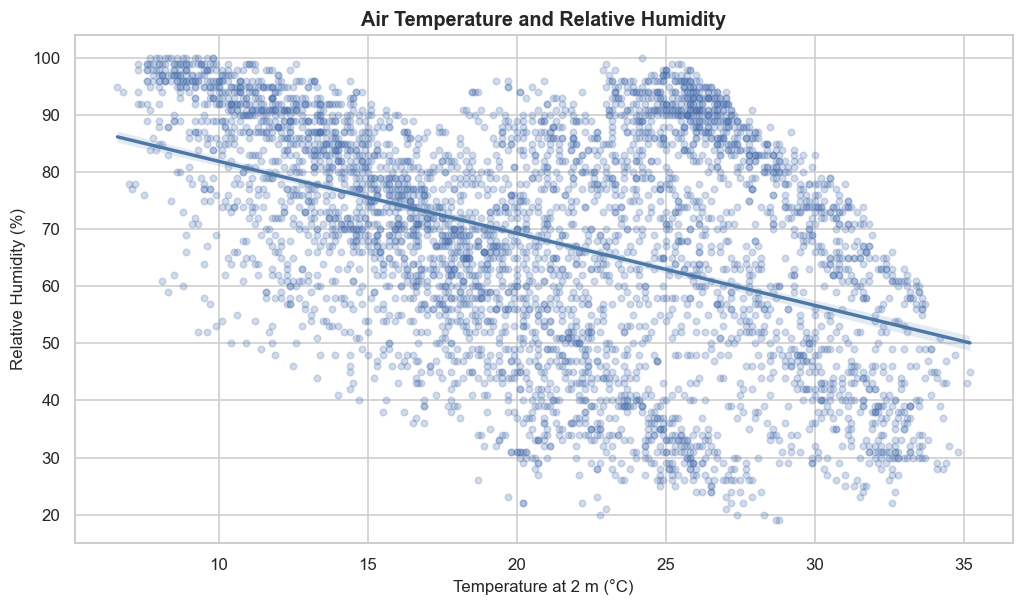

Observation: temperature and relative humidity have a correlation of -0.43.


In [75]:
sns.regplot(data=weather, x='temperature_2m_c', y='relative_humidity_2m_pct', scatter_kws={'alpha': 0.25, 's': 18}, line_kws={'color': '#4C78A8'})
plt.title('Air Temperature and Relative Humidity')
plt.xlabel('Temperature at 2 m (°C)')
plt.ylabel('Relative Humidity (%)')
plt.show()
print(f'Observation: temperature and relative humidity have a correlation of {correlation_matrix.loc["temperature_2m_c", "relative_humidity_2m_pct"]:.2f}.')

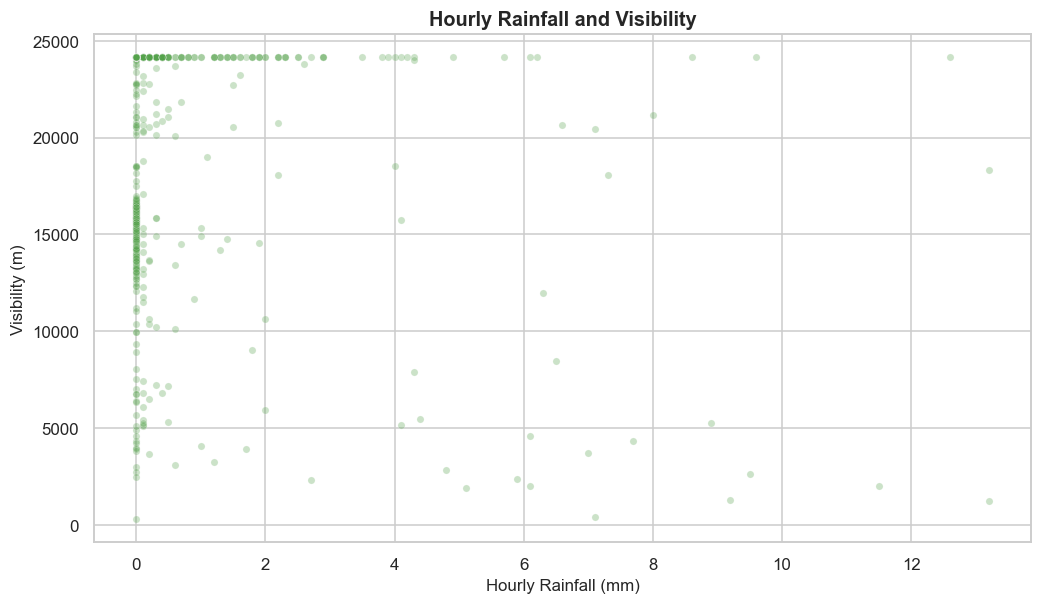

Observation: rainfall and visibility have a correlation of -0.34; this association should be interpreted alongside the concentration of zero-rainfall hours.


In [76]:
sns.scatterplot(data=weather, x='rain_mm', y='visibility_m', alpha=0.30, s=22, color='#54A24B')
plt.title('Hourly Rainfall and Visibility')
plt.xlabel('Hourly Rainfall (mm)')
plt.ylabel('Visibility (m)')
plt.show()
print(f'Observation: rainfall and visibility have a correlation of {correlation_matrix.loc["rain_mm", "visibility_m"]:.2f}; this association should be interpreted alongside the concentration of zero-rainfall hours.')

## 7. Weather Code Analysis

WMO weather codes provide a categorical summary of prevailing conditions. Their frequency and percentage distribution show how often each reported condition occurred during the analysis period.

In [77]:
weather_code_summary = (
    weather['weather_code_wmo']
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis('weather_code_wmo')
    .to_frame('count')
)
weather_code_summary['percentage'] = (weather_code_summary['count'] / len(weather) * 100).round(2)
display(weather_code_summary)
print(f'Observation: weather code {weather_code_summary["count"].idxmax()} is most frequent ({weather_code_summary["percentage"].max():.2f}% of observations).')

,count,percentage
weather_code_wmo,,
0,3171,73.00
1,265,6.10
2,115,2.65
3,496,11.42
51,171,3.94
53,29,0.67
55,11,0.25
61,38,0.87
63,37,0.85


Observation: weather code 0 is most frequent (73.00% of observations).


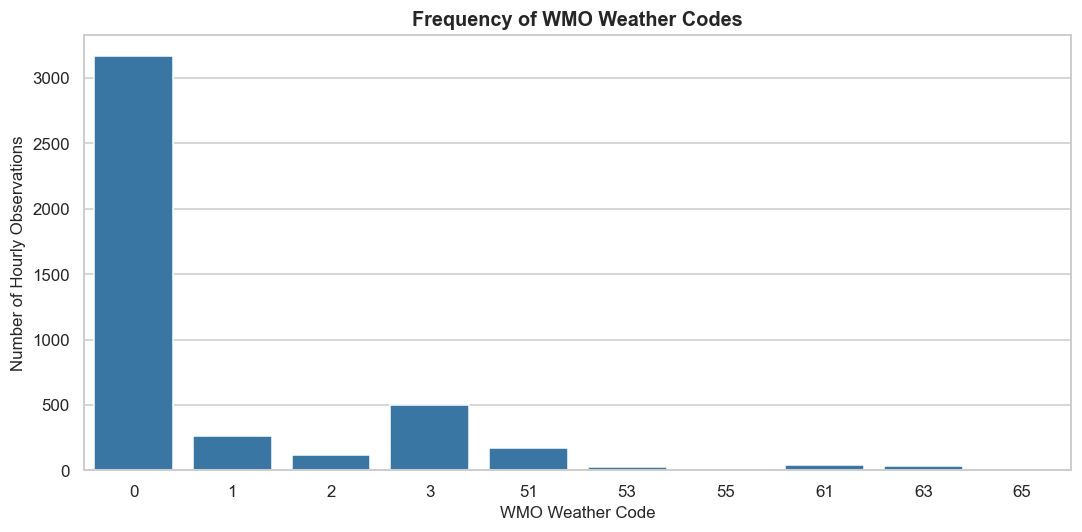

Observation: the distribution shows the relative prevalence of reported weather conditions over the study period.


In [78]:
plt.figure(figsize=(10, 5))
sns.countplot(data=weather, x='weather_code_wmo', color='#2878B5', order=weather_code_summary.index)
plt.title('Frequency of WMO Weather Codes')
plt.xlabel('WMO Weather Code')
plt.ylabel('Number of Hourly Observations')
plt.tight_layout()
plt.show()
print('Observation: the distribution shows the relative prevalence of reported weather conditions over the study period.')

## 8. Extreme Weather Events

Extreme observations are identified directly from the hourly record. Reporting their timestamps and accompanying conditions provides a concise audit of unusual weather during the study period.

In [79]:
extreme_definitions = {
    'Highest rainfall': ('rain_mm', 'max'),
    'Highest temperature': ('temperature_2m_c', 'max'),
    'Lowest temperature': ('temperature_2m_c', 'min'),
    'Highest humidity': ('relative_humidity_2m_pct', 'max'),
    'Lowest visibility': ('visibility_m', 'min')
}

extreme_records = []
for event, (column, operation) in extreme_definitions.items():
    value = weather[column].max() if operation == 'max' else weather[column].min()
    records = weather.loc[weather[column].eq(value), ['time', column, 'weather_code_wmo']].copy()
    records.insert(0, 'event', event)
    records = records.rename(columns={column: 'extreme_value'})
    extreme_records.append(records)

extreme_weather_events = pd.concat(extreme_records, ignore_index=True)
display(extreme_weather_events)

,event,time,extreme_value,weather_code_wmo
0,Highest rainfall,2024-09-12 06:00:00,13.20,65
1,Highest rainfall,2024-09-18 21:00:00,13.20,65
2,Highest temperature,2024-10-02 14:00:00,35.20,0
3,Lowest temperature,2024-12-16 07:00:00,6.60,0
4,Highest humidity,2024-09-20 06:00:00,100.00,3
5,Highest humidity,2024-12-17 04:00:00,100.00,3
6,Highest humidity,2025-01-01 00:00:00,100.00,3
7,Highest humidity,2025-01-03 04:00:00,100.00,3
8,Highest humidity,2025-01-03 05:00:00,100.00,3
9,Highest humidity,2025-01-04 01:00:00,100.00,3


In [80]:
print(
    f'Observation: maximum hourly rainfall was {weather["rain_mm"].max():.1f} mm; '
    f'highest and lowest temperatures were {weather["temperature_2m_c"].max():.1f}°C and {weather["temperature_2m_c"].min():.1f}°C; '
    f'highest humidity was {weather["relative_humidity_2m_pct"].max():.0f}%; '
    f'and lowest visibility was {weather["visibility_m"].min():.0f} m.'
)

Observation: maximum hourly rainfall was 13.2 mm; highest and lowest temperatures were 35.2°C and 6.6°C; highest humidity was 100%; and lowest visibility was 300 m.


## 9. Final Weather EDA Summary

The following cell generates a concise, markdown-ready summary from the computed results. It is suitable for adaptation into the weather-data subsection of the research report after the notebook has been executed.

In [81]:
report_summary = f"""### Weather EDA Summary

The cleaned Delhi weather dataset contains **{len(weather):,} hourly observations** from **{weather['time'].min():%d %B %Y}** to **{weather['time'].max():%d %B %Y}**. Air temperature ranged from **{weather['temperature_2m_c'].min():.1f}°C** to **{weather['temperature_2m_c'].max():.1f}°C**, while total precipitation over the period was **{weather['precipitation_mm'].sum():.1f} mm**.

Hourly aggregation indicates that temperature, humidity, cloud cover, rainfall, and wind speed vary systematically across the day. Monthly aggregation further shows seasonal change across the September-to-February study window, with the warmest monthly mean temperature in **{monthly_temperature.idxmax()}** and the highest total rainfall in **{monthly_rainfall.idxmax()}**.

The correlation analysis shows a particularly strong association between air temperature and apparent temperature (**r = {correlation_matrix.loc['temperature_2m_c', 'apparent_temperature_c']:.2f}**). The most frequently recorded WMO weather code was **{weather_code_summary['count'].idxmax()}**, accounting for **{weather_code_summary['percentage'].max():.2f}%** of hourly observations. Extreme conditions included maximum hourly rainfall of **{weather['rain_mm'].max():.1f} mm** and minimum visibility of **{weather['visibility_m'].min():.0f} m**.

These findings describe the weather context of the study period and provide a transparent basis for later work that examines weather alongside Delhi Metro ridership.
"""
print(report_summary)

### Weather EDA Summary

The cleaned Delhi weather dataset contains **4,344 hourly observations** from **01 September 2024** to **28 February 2025**. Air temperature ranged from **6.6°C** to **35.2°C**, while total precipitation over the period was **413.8 mm**.

Hourly aggregation indicates that temperature, humidity, cloud cover, rainfall, and wind speed vary systematically across the day. Monthly aggregation further shows seasonal change across the September-to-February study window, with the warmest monthly mean temperature in **2024-09** and the highest total rainfall in **2024-09**.

The correlation analysis shows a particularly strong association between air temperature and apparent temperature (**r = 0.97**). The most frequently recorded WMO weather code was **0**, accounting for **73.00%** of hourly observations. Extreme conditions included maximum hourly rainfall of **13.2 mm** and minimum visibility of **300 m**.

These findings describe the weather context of the study peri